# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [10]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

### Load Data

Load data and select features with an SQL query through the duckdb.

Based on the EDA results, `year`, `patch`, and `gamelength` are removed because they have 0.00 correlation with the target variable `result`.
On the other hand, `towers`, `assists`, and `goldspent` are removed because they have high correlation with other variables, which may cause multicollinearity during modeling. 

In [15]:
con = duckdb.connect("lol_predictors.duckdb")

def data_selection(df, included_cols):
    # Choose the dataset using an SQL query
    df = con.execute(f"""
    SELECT {", ".join(included_cols)}
    FROM {df}
    WHERE position = 'team';
    """).df()

    return df

# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'teamname', 'result', 'kills',
                   'deaths', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'split']

df_selected = "df_2014" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include)

con.close()

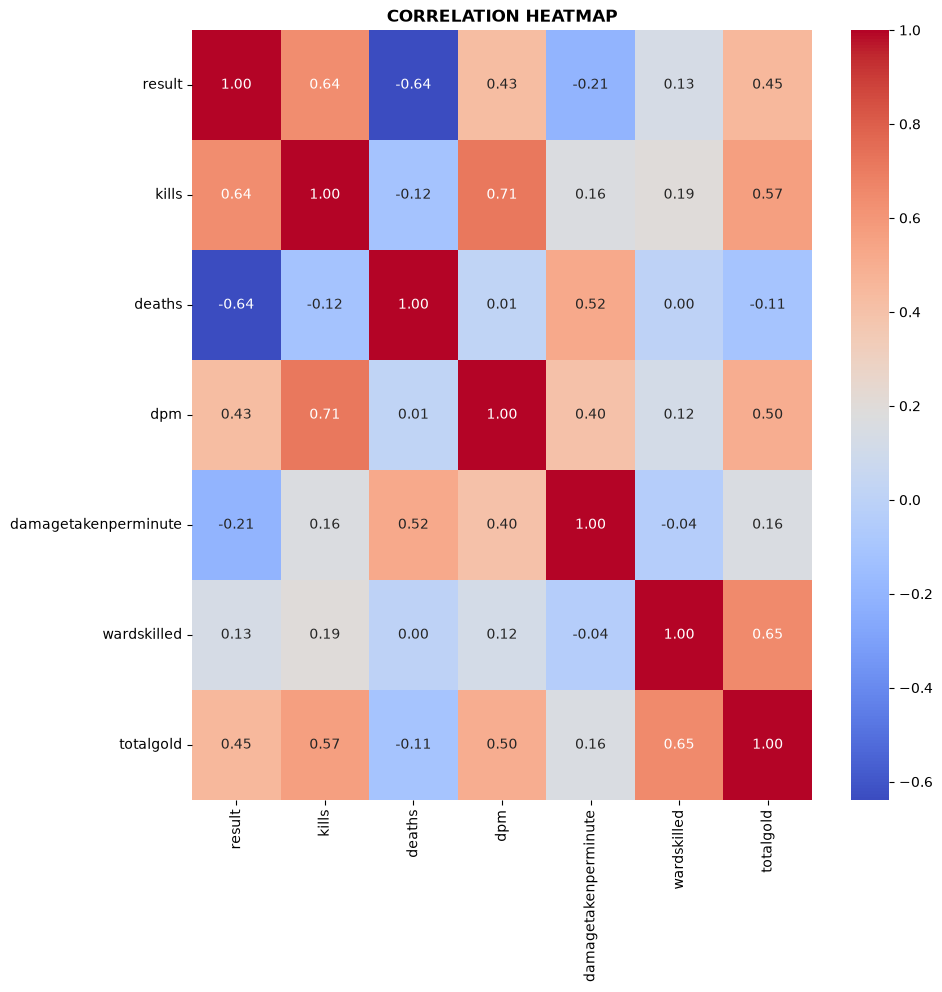

In [16]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=12, fontweight="bold")
plt.show()

### Data Processing

For **data imputation**, only the feature `split` has missing values based on df_2014's EDA. We can use the previous value for each NaN since there's only two values, which are `Summer` and `Spring`, and they are sorted chronologically.

In [17]:
df['split'] = df['split'].ffill()

We will **trim outliers** because even the feature `wardskilled` that has the highest outlier percentage only has <2% of outliers.

In [20]:
num_cols = df.select_dtypes(include=["number"]).columns.tolist()

for col in num_cols:
    # Setting the IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    IQR_multiplier = 1.5

    # Standard 1.5 multiplier for outlier bounds
    lower_bound = Q1 - IQR_multiplier * IQR
    upper_bound = Q3 + IQR_multiplier * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]